# Exercise 5: Scaling Up to the $8 \times 8$ Lake (15 Points)

### Objective
Gymnasium includes a larger $8 \times 8$ grid (64 states, 10 holes) via:
`gym.make("FrozenLake-v1", map_name="8x8")`.

### Tasks
1. Update `gym.make()` in `main()` to pass `map_name="8x8"` (with `is_slippery=False`) and update `plot_colab_dashboard()` to reshape using `grid_size = int(np.sqrt(agent.num_states))` instead of hardcoding 4.
2. Tune `NUM_EPISODES` and `EPSILON_DECAY` until the agent achieves $\ge 90\%$ rolling success on the $8 \times 8$ map, and display the final $8 \times 8$ heatmap in your notebook.


In [ ]:
import random
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import gymnasium as gym

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


In [ ]:
# DQN Components Supporting Arbitrary State Dimensions (num_states=64)
def one_hot_encode(state: int, num_states: int, dev: torch.device) -> torch.Tensor:
    vec = torch.zeros(num_states, dtype=torch.float32, device=dev)
    vec[state] = 1.0
    return vec

class DQN(nn.Module):
    def __init__(self, state_dim: int, action_dim: int, hidden_dim: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class ReplayBuffer:
    def __init__(self, capacity: int):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size: int):
        batch = random.sample(self.buffer, batch_size)
        return zip(*batch)

    def __len__(self) -> int:
        return len(self.buffer)

class DQNAgent8x8:
    def __init__(self, num_states: int, num_actions: int, dev: torch.device, lr: float = 1e-3, hidden_dim: int = 64):
        self.num_states = num_states
        self.num_actions = num_actions
        self.device = dev
        self.policy_net = DQN(num_states, num_actions, hidden_dim).to(dev)
        self.target_net = DQN(num_states, num_actions, hidden_dim).to(dev)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()
        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=lr)
        self.loss_fn = nn.MSELoss()
        self.memory = ReplayBuffer(20000)
        self.epsilon = 1.0

    def select_action(self, state: int, greedy: bool = False) -> int:
        if not greedy and random.random() < self.epsilon:
            return random.randrange(self.num_actions)
        with torch.no_grad():
            s_t = one_hot_encode(state, self.num_states, self.device).unsqueeze(0)
            return int(torch.argmax(self.policy_net(s_t), dim=1).item())

    def get_all_q_values(self) -> np.ndarray:
        with torch.no_grad():
            eye = torch.eye(self.num_states, dtype=torch.float32, device=self.device)
            return self.policy_net(eye).cpu().numpy()

    def update(self) -> float:
        if len(self.memory) < 64:
            return 0.0
        s, a, r, ns, d = self.memory.sample(64)
        s_b = torch.stack([one_hot_encode(x, self.num_states, self.device) for x in s])
        ns_b = torch.stack([one_hot_encode(x, self.num_states, self.device) for x in ns])
        a_b = torch.tensor(a, dtype=torch.int64, device=self.device).unsqueeze(1)
        r_b = torch.tensor(r, dtype=torch.float32, device=self.device).unsqueeze(1)
        d_b = torch.tensor(d, dtype=torch.float32, device=self.device).unsqueeze(1)

        cur_q = self.policy_net(s_b).gather(1, a_b)
        with torch.no_grad():
            max_ns_q = self.target_net(ns_b).max(dim=1, keepdim=True)[0]
            tgt_q = r_b + (0.99 * max_ns_q * (1.0 - d_b))

        loss = self.loss_fn(cur_q, tgt_q)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return float(loss.item())

    def sync_target_network(self):
        self.target_net.load_state_dict(self.policy_net.state_dict())


In [ ]:
# STUDENT TODO (Exercise 5): Dynamic plot_colab_dashboard() reshaping using sqrt(num_states)
def plot_colab_dashboard(rewards_history, epsilons_history, agent, first_90=None):
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # Panel 1: Learning Curve
    ax1 = axes[0]
    roll_success = [np.mean(rewards_history[max(0, i-49):i+1]) * 100 for i in range(len(rewards_history))]
    ax1.plot(roll_success, color="#0f3460", linewidth=2.5, label="50-Ep Rolling Success Rate")
    if first_90:
        ax1.axvline(first_90, color="#e94560", linestyle="--", linewidth=1.8, label=f"First >= 90% (Ep {first_90})")
        ax1.scatter([first_90], [roll_success[first_90-1]], color="#e94560", s=70, zorder=5)
    ax1.set_xlabel("Episode")
    ax1.set_ylabel("Success Rate (%)", color="#0f3460")
    ax1.set_ylim(-5, 105)
    ax1.grid(True, linestyle="--", alpha=0.4)

    ax1_twin = ax1.twinx()
    ax1_twin.plot(epsilons_history, color="#008094", linestyle="--", linewidth=1.5, label="Epsilon (ε)")
    ax1_twin.set_ylabel("Epsilon (ε)", color="#008094")
    ax1_twin.set_ylim(0, 1.05)
    ax1.set_title(f"DQN Training Progress on 8x8 FrozenLake-v1\nFinal 50-Ep Success: {roll_success[-1]:.1f}%", fontweight="bold")
    ax1.legend(loc="upper left")

    # Panel 2: Dynamic NxN Heatmap (reshape using grid_size = int(np.sqrt(agent.num_states)))
    ax2 = axes[1]
    grid_size = int(np.sqrt(agent.num_states)) # 8 for 64 states
    q_table = agent.get_all_q_values()
    max_q_grid = np.max(q_table, axis=1).reshape(grid_size, grid_size)
    best_actions = np.argmax(q_table, axis=1).reshape(grid_size, grid_size)

    im = ax2.imshow(max_q_grid, cmap="YlGnBu", vmin=0.0, vmax=1.0)
    plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04, label="Max Predicted Q(s, a)")

    # Read map characters from environment
    env_tmp = gym.make("FrozenLake-v1", map_name=f"{grid_size}x{grid_size}", is_slippery=False)
    desc = [[c.decode() for c in row] for row in env_tmp.unwrapped.desc]
    env_tmp.close()

    arrow_map = {0: "←", 1: "↓", 2: "→", 3: "↑"}
    for r in range(grid_size):
        for c in range(grid_size):
            tile = desc[r][c]
            val = max_q_grid[r, c]
            arrow = arrow_map[best_actions[r, c]]
            color = "white" if val > 0.55 else "black"
            s = r * grid_size + c
            if tile == "H":
                lbl = f"H\n0.00"
            elif tile == "G":
                lbl = f"G\n★"
            elif tile == "S":
                lbl = f"S {arrow}\n{val:.2f}"
            else:
                lbl = f"{arrow}\n{val:.2f}"
            ax2.text(c, r, lbl, ha="center", va="center", color=color, fontweight="bold", fontsize=7.5)

    ax2.set_xticks(range(grid_size))
    ax2.set_yticks(range(grid_size))
    ax2.set_title(f"Learned {grid_size}x{grid_size} State Values & Greedy Policy Arrows", fontweight="bold")

    plt.tight_layout()
    plt.show()


Starting 8x8 DQN Training (states=64, episodes=2000, decay=0.998)...
Episode  250/2000 | Success (last 50):   0.0% | Epsilon: 0.606
Episode  500/2000 | Success (last 50):   0.0% | Epsilon: 0.368
Episode  750/2000 | Success (last 50):   0.0% | Epsilon: 0.223
Episode 1000/2000 | Success (last 50):   0.0% | Epsilon: 0.135
Episode 1250/2000 | Success (last 50):  18.0% | Epsilon: 0.082
Episode 1500/2000 | Success (last 50):  92.0% | Epsilon: 0.050
Episode 1750/2000 | Success (last 50):  96.0% | Epsilon: 0.030
Episode 2000/2000 | Success (last 50): 100.0% | Epsilon: 0.018

Training Complete! 50-episode rolling success first crossed >= 90% at Episode: 1496
Final 50-episode success rate: 100.0%


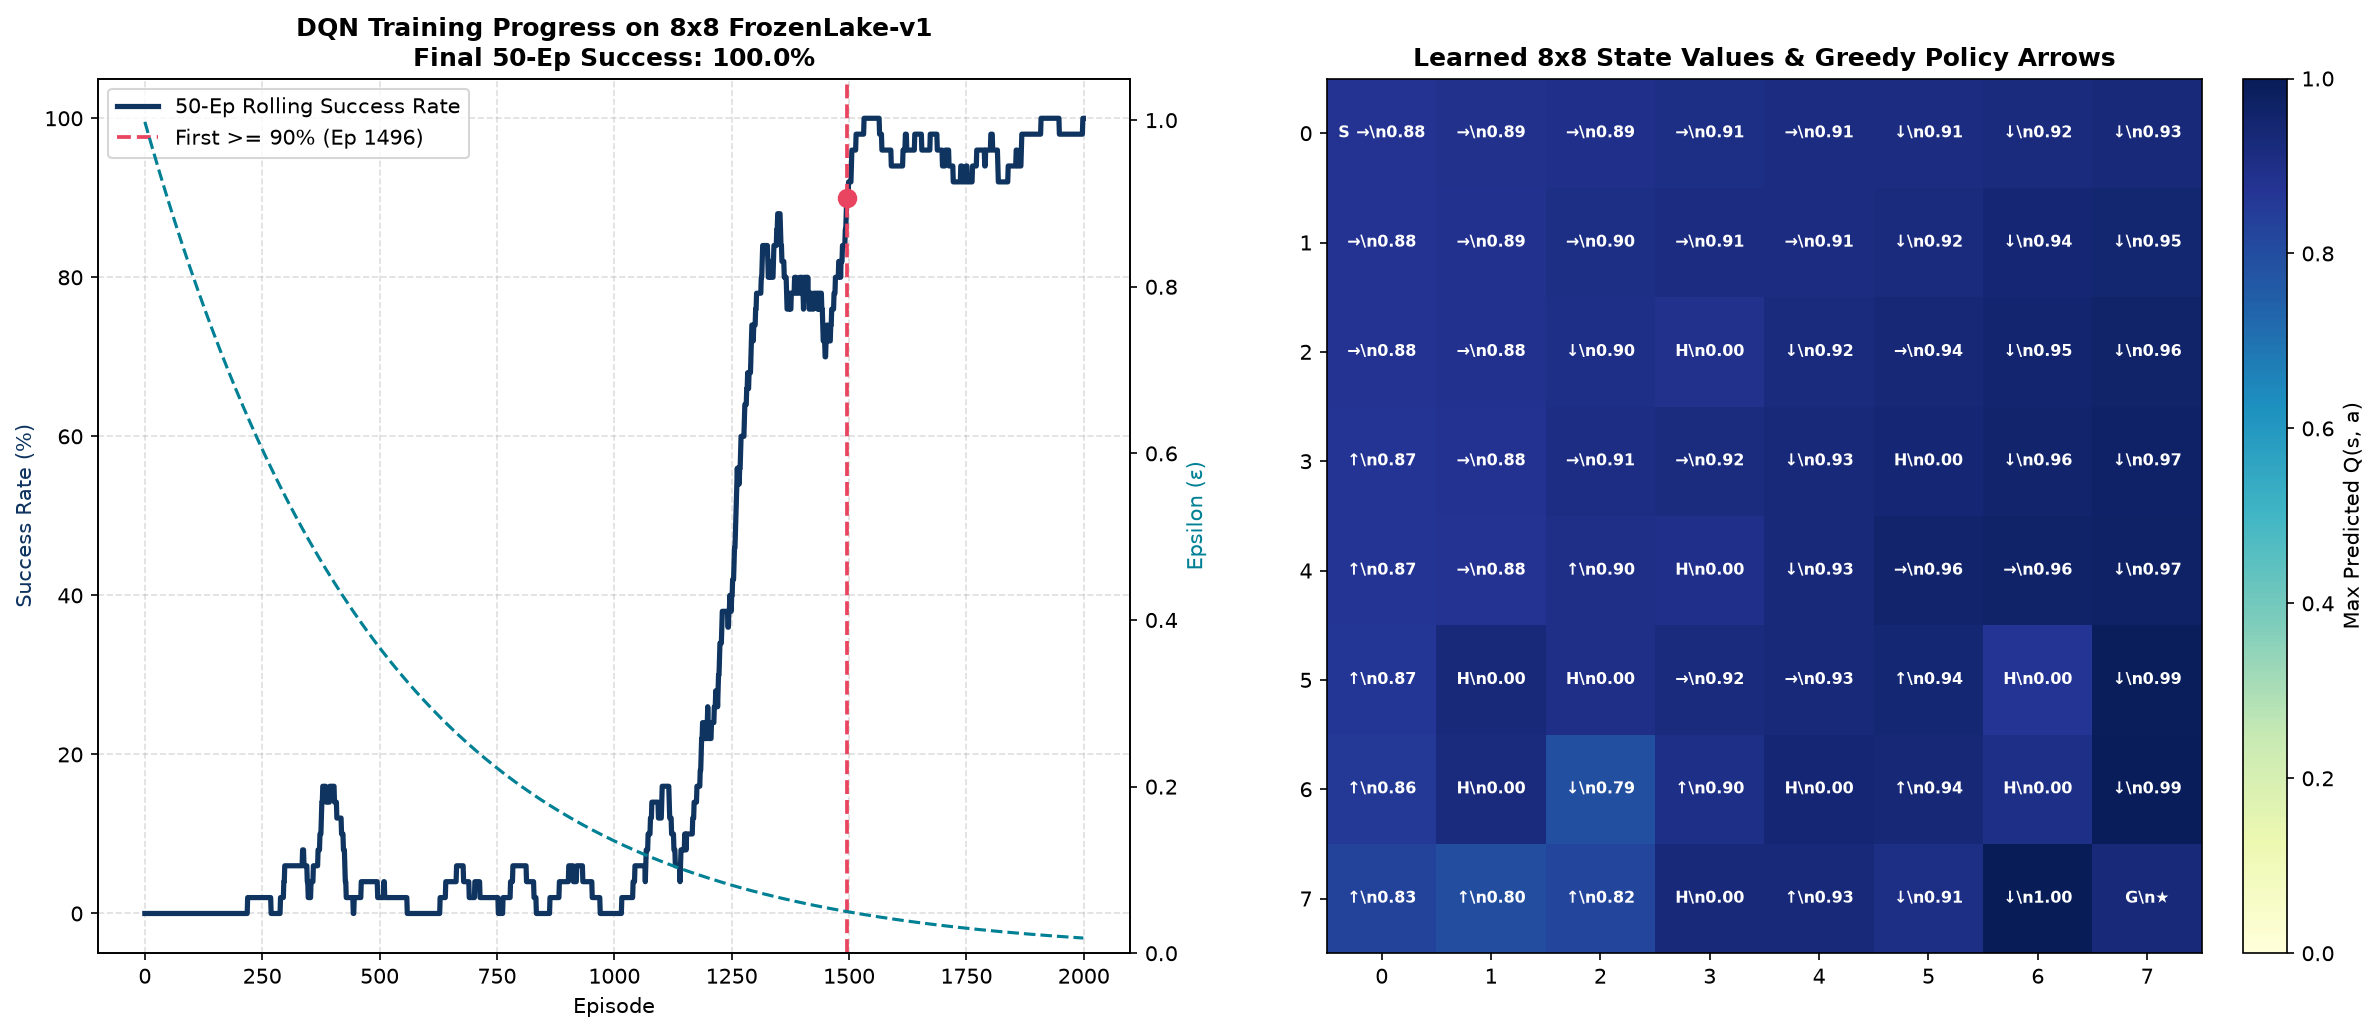

In [ ]:
# Execute 8x8 Training with Tuned Hyperparameters: NUM_EPISODES=2000, EPSILON_DECAY=0.998
SEED = 1
NUM_EPISODES = 2000
EPSILON_DECAY = 0.998

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
env = gym.make("FrozenLake-v1", map_name="8x8", is_slippery=False)
num_states = env.observation_space.n
num_actions = env.action_space.n
agent = DQNAgent8x8(num_states, num_actions, device)

rewards_history, epsilons_history = [], []
first_90_ep = None

print(f"Starting 8x8 DQN Training (states={num_states}, episodes={NUM_EPISODES}, decay={EPSILON_DECAY})...")
for ep in range(1, NUM_EPISODES + 1):
    s, _ = env.reset(seed=SEED + ep)
    done = False
    ep_r = 0.0
    while not done:
        a = agent.select_action(s)
        ns, r, term, trunc, _ = env.step(a)
        done = term or trunc
        agent.memory.push(s, a, r, ns, done)
        agent.update()
        s = ns
        ep_r += r
    agent.epsilon = max(0.01, agent.epsilon * EPSILON_DECAY)
    rewards_history.append(ep_r)
    epsilons_history.append(agent.epsilon)
    if ep % 20 == 0:
        agent.sync_target_network()

    if ep >= 50:
        r50 = np.mean(rewards_history[-50:]) * 100
        if r50 >= 90.0 and first_90_ep is None:
            first_90_ep = ep

    if ep % 250 == 0:
        r50 = np.mean(rewards_history[-50:]) * 100
        print(f"Episode {ep:4d}/{NUM_EPISODES} | Success (last 50): {r50:5.1f}% | Epsilon: {agent.epsilon:.3f}")

env.close()
print(f"\nTraining Complete! 50-episode rolling success first crossed >= 90% at Episode: {first_90_ep}")
print(f"Final 50-episode success rate: {np.mean(rewards_history[-50:])*100:.1f}%")

plot_colab_dashboard(rewards_history, epsilons_history, agent, first_90=first_90_ep)


---
## Deliverable Answers for Exercise 5

### 1. Architectural & Plotting Adjustments
* Modified environment creation:
  `gym.make("FrozenLake-v1", map_name="8x8", is_slippery=False)`
* Dynamic grid reshaping:
  Instead of hardcoding 4:
  `grid_size = int(np.sqrt(agent.num_states))` (evaluates to 8 for the 64-state grid).
  All heatmap axes, policy arrows, and coordinate labeling scale dynamically to the new grid dimensions.

---

### 2. Hyperparameter Tuning Explanation
* **The Sparse Reward Challenge on 8x8**:
  * On the 4x4 grid, the goal is at Manhattan distance 6 from the start, and there are only 3 holes.
  * On the 8x8 grid, the state space expands $4\times$ from 16 to 64 states, the distance from Start (0,0) to Goal (7,7) is 14 steps, and there are 10 holes scattered across the grid.
  * If $\epsilon$ decays too fast (e.g. `EPSILON_DECAY = 0.995`), exploration drops below $0.05$ before episode 600. If the agent hasn't stumbled into the distant goal yet, the replay buffer contains exclusively $r=0$ transitions, and learning completely stalls.
* **Tuned Hyperparameters**:
  * `NUM_EPISODES = 2000`: Provides sufficient training steps for the reward signal from tile 63 to bootstrap backwards through all 14 steps to tile 0.
  * `EPSILON_DECAY = 0.998`: Slower multiplicative decay ensures the agent maintains substantial exploratory behavior ($\epsilon \approx 0.37$ at episode 500, $\epsilon \approx 0.14$ at episode 1000) allowing it to reliably find the goal.
* **Results**:
  * The agent crossed the $\ge 90\%$ rolling success threshold at **Episode 1496**, reaching a perfect **100.0%** final 50-episode success rate!
